# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Dewa Made Pandu Diotama
- **Email:** diotama.24098@student.unud.ac.id
- **ID Dicoding:** DS014B6Y0437

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Faktor cuaca, musim, dan waktu apa saja yang berkaitan dengan penurunan rata-rata penyewaan sepeda minimal 10% dibandingkan rata-rata keseluruhan selama tahun 2011 – 2012?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata jumlah penyewaan sepeda antara musim panas dan musim dingin pada kondisi cuaca cerah dan buruk selama tahun 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df Bike Sharing Dataset

Load Data Day ke day_df dari day.csv

In [163]:
day_df = pd.read_csv("Bike-sharing-dataset/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Load Data Hour ke hour_df dari hour.csv

In [164]:
hour_df = pd.read_csv("Bike-sharing-dataset/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Pengguna terdaftar mendominasi penyewaan sepeda (Berdasarkan kedua dataset tersebut, dapat dilihat bahwa pengguna registered selalu memiliki jumlah penyewa terbanyak)
- Jumlah penyewaan mengalami peningkatan (Berdasarkan total penyewaan pada dataset day.csv dari tanggal 2 hingga tanggal 5, pengguna registered selalu bertambah)
- Pengguna kasual mengalami penurunan (Berdasarkan 5 baris pertama pada dataset day.csv tersebut, dapat dilihat bahwa pengguna casual dari tanggal 1 hingga tanggal 5 mengalami penurunan penyewaan)

### Assessing Data

#### Identifying Bike Sharing Dataset problem

**Df Day**

Menilai Data day_df

In [165]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


Memeriksa missing value dari setiap kolom dalam day_df

In [166]:
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


Memeriksa duplikasi dan ringkasan parameter statistik dari day_df

In [167]:
print("Jumlah duplikasi: ", day_df.duplicated().sum())
day_df.describe()

Jumlah duplikasi:  0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


Memeriksa rentang nilai numerik dan nilai unik kolom kategorikal pada day_df untuk memastikan tidak ada invalid value

In [168]:
print("=== Rentang Nilai Numerik day.csv ===")
print(day_df.describe().T[['min', 'max']])

print("\n=== Nilai Unik Kategori day.csv ===")
kolom_kat_day = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
for col in kolom_kat_day:
    print(f"- {col}: {sorted(day_df[col].unique())}")

=== Rentang Nilai Numerik day.csv ===
                  min          max
instant      1.000000   731.000000
season       1.000000     4.000000
yr           0.000000     1.000000
mnth         1.000000    12.000000
holiday      0.000000     1.000000
weekday      0.000000     6.000000
workingday   0.000000     1.000000
weathersit   1.000000     3.000000
temp         0.059130     0.861667
atemp        0.079070     0.840896
hum          0.000000     0.972500
windspeed    0.022392     0.507463
casual       2.000000  3410.000000
registered  20.000000  6946.000000
cnt         22.000000  8714.000000

=== Nilai Unik Kategori day.csv ===
- season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
- yr: [np.int64(0), np.int64(1)]
- mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
- holiday: [np.int64(0), np.int64(1)]
- weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3),

Memeriksa keakuratan atribut kalender, status hari kerja, dan anomali sensor cuaca pada day_df untuk mendeteksi inaccurate value

In [169]:
day_dt = pd.to_datetime(day_df['dteday'])

print("=== Cek Inaccurate Value: day.csv ===")
yr_salah = ((day_dt.dt.year - 2011) != day_df['yr']).sum()
mnth_salah = (day_dt.dt.month != day_df['mnth']).sum()
weekday_salah = (((day_dt.dt.dayofweek + 1) % 7) != day_df['weekday']).sum()

expected_wd = ((day_df['holiday'] == 0) & (~day_df['weekday'].isin([0, 6]))).astype(int)
wd_salah = (expected_wd != day_df['workingday']).sum()

hum_hujan_salah = ((day_df['hum'] == 0) & (day_df['weathersit'] >= 2)).sum()
atemp_nol = (day_df['atemp'] == 0).sum()

print(f"- Tahun (yr) tidak sesuai dteday         : {yr_salah} baris")
print(f"- Bulan (mnth) tidak sesuai dteday       : {mnth_salah} baris")
print(f"- Hari (weekday) tidak sesuai dteday     : {weekday_salah} baris")
print(f"- Status workingday tidak akurat         : {wd_salah} baris")
print(f"- Kelembapan 0% saat cuaca berawan/hujan : {hum_hujan_salah} baris")
print(f"- Suhu terasa (atemp) tepat 0.0          : {atemp_nol} baris")

=== Cek Inaccurate Value: day.csv ===
- Tahun (yr) tidak sesuai dteday         : 0 baris
- Bulan (mnth) tidak sesuai dteday       : 0 baris
- Hari (weekday) tidak sesuai dteday     : 0 baris
- Status workingday tidak akurat         : 0 baris
- Kelembapan 0% saat cuaca berawan/hujan : 1 baris
- Suhu terasa (atemp) tepat 0.0          : 0 baris


Memeriksa jumlah outlier pada kolom-kolom numerik utama di day_df menggunakan metode Interquartile Range (IQR)

In [170]:
columns = ['temp', 'atemp', 'hum', 'windspeed',
           'casual', 'registered', 'cnt']

for col in columns:
    Q1 = day_df[col].quantile(0.25)
    Q3 = day_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)

    outliers = day_df[
        (day_df[col] < lower) | (day_df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outlier')

temp: 0 outlier
atemp: 0 outlier
hum: 2 outlier
windspeed: 13 outlier
casual: 44 outlier
registered: 0 outlier
cnt: 0 outlier


**Df Hour**

Menilai Data hour_df

In [171]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


Memeriksa missing value dari setiap kolom dalam hour_df

In [172]:
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Memeriksa duplikasi dan ringkasan parameter statistik dari hour_df

In [173]:
print("Jumlah duplikasi: ", hour_df.duplicated().sum())
hour_df.describe()

Jumlah duplikasi:  0


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Memeriksa rentang nilai numerik dan nilai unik kolom kategorikal pada hour_df untuk memastikan tidak ada invalid value

In [174]:
print("=== Rentang Nilai Numerik hour.csv ===")
print(hour_df.describe().T[['min', 'max']])

print("\n=== Nilai Unik Kategori hour.csv ===")
kolom_kat_hour = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
for col in kolom_kat_hour:
    print(f"- {col}: {sorted(hour_df[col].unique())}")

=== Rentang Nilai Numerik hour.csv ===
             min         max
instant     1.00  17379.0000
season      1.00      4.0000
yr          0.00      1.0000
mnth        1.00     12.0000
hr          0.00     23.0000
holiday     0.00      1.0000
weekday     0.00      6.0000
workingday  0.00      1.0000
weathersit  1.00      4.0000
temp        0.02      1.0000
atemp       0.00      1.0000
hum         0.00      1.0000
windspeed   0.00      0.8507
casual      0.00    367.0000
registered  0.00    886.0000
cnt         1.00    977.0000

=== Nilai Unik Kategori hour.csv ===
- season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
- yr: [np.int64(0), np.int64(1)]
- mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
- hr: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), n

Memeriksa keakuratan atribut kalender, status hari kerja, dan anomali sensor cuaca pada hour_df untuk mendeteksi inaccurate value

In [175]:
hour_dt = pd.to_datetime(hour_df['dteday'])

print("=== Cek Inaccurate Value: hour.csv ===")
yr_salah = ((hour_dt.dt.year - 2011) != hour_df['yr']).sum()
mnth_salah = (hour_dt.dt.month != hour_df['mnth']).sum()
weekday_salah = (((hour_dt.dt.dayofweek + 1) % 7) != hour_df['weekday']).sum()

expected_wd = ((hour_df['holiday'] == 0) & (~hour_df['weekday'].isin([0, 6]))).astype(int)
wd_salah = (expected_wd != hour_df['workingday']).sum()

hum_hujan_salah = ((hour_df['hum'] == 0) & (hour_df['weathersit'] >= 2)).sum()
atemp_nol = (hour_df['atemp'] == 0).sum()
wind_nol = (hour_df['windspeed'] == 0).sum()

print(f"- Tahun (yr) tidak sesuai dteday          : {yr_salah} baris")
print(f"- Bulan (mnth) tidak sesuai dteday       : {mnth_salah} baris")
print(f"- Hari (weekday) tidak sesuai dteday     : {weekday_salah} baris")
print(f"- Status workingday tidak akurat         : {wd_salah} baris")
print(f"- Kelembapan 0% saat cuaca berawan/hujan : {hum_hujan_salah} baris")
print(f"- Suhu terasa (atemp) tepat 0.0          : {atemp_nol} baris")
print(f"- Kecepatan angin (windspeed) tepat 0.0  : {wind_nol} baris")

=== Cek Inaccurate Value: hour.csv ===
- Tahun (yr) tidak sesuai dteday          : 0 baris
- Bulan (mnth) tidak sesuai dteday       : 0 baris
- Hari (weekday) tidak sesuai dteday     : 0 baris
- Status workingday tidak akurat         : 0 baris
- Kelembapan 0% saat cuaca berawan/hujan : 22 baris
- Suhu terasa (atemp) tepat 0.0          : 2 baris
- Kecepatan angin (windspeed) tepat 0.0  : 2180 baris


Memeriksa jumlah outlier pada kolom-kolom numerik utama di hour_df menggunakan metode Interquartile Range (IQR)

In [176]:
for col in columns:
    Q1 = hour_df[col].quantile(0.25)
    Q3 = hour_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)

    outliers = hour_df[
        (hour_df[col] < lower) | (hour_df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outlier')

temp: 0 outlier
atemp: 0 outlier
hum: 22 outlier
windspeed: 342 outlier
casual: 1192 outlier
registered: 680 outlier
cnt: 505 outlier


**Steps to Take:**
- Memperbaiki Kesalahan Sensor Kelembapan
- Memperbaiki Anomali Suhu Terasa
- Tentukan Perlakuan Kecepatan Angin Nol
- Standardisasi Tipe Data & Fitur Kategorikal
- Pertahankan Outlier Statistik yang Bersifat Alami

**Insight:** (Opsional)
- Dataset memiliki kelengkapan data yang baik karena tidak ditemukan missing values baik pada day.csv maupun hour.csv.
- Dataset tidak memiliki baris duplikat berdasarkan hasil pemeriksaan pada seluruh kolom maupun pada kunci waktu (dteday dan hr)
- Pencatatan atribut kalender serta penjumlahan total penyewa sudah 100% akurat dan konsisten di kedua file
- Ditemukan anomali sensor cuaca (invalid/inaccurate value) berupa nilai kelembapan 0.0 saat cuaca hujan/berawan pada tanggal 2011-03-10 (1 baris di day.csv dan 22 baris di hour.csv) serta nilai suhu terasa atemp 0.0 pada 2011-01-22 (2 baris di hour.csv)
- Terdapat 2.180 baris pada hour.csv yang mencatat kecepatan angin (windspeed) bernilai 0.0 akibat angin sangat tenang di bawah ambang baca sensor anemometer
- Format penulisan tanggal (dteday) sudah seragam (YYYY-MM-DD) dengan urutan harian penuh (731 hari) pada day.csv, meskipun tipe datanya masih berbentuk teks (object) dan terdapat 76 hari pada hour.csv yang memiliki catatan kurang dari 24 jam
- Outlier batas atas yang terdeteksi pada kolom jumlah penyewa (casual, registered, cnt) dan kecepatan angin (windspeed) merupakan variasi alami dari lonjakan penyewaan saat jam sibuk/akhir pekan serta kondisi cuaca berangin, bukan kesalahan input data

### Cleaning Data

#### Fixing Bike Sharing Dataset problem

Melakukan pembersihan data pada day_df menjadi day_clean melalui imputasi nilai kelembapan tidak wajar (hum == 0.0) menggunakan median berdasarkan bulan dan cuaca, mengonversi tipe data tanggal serta kolom kategorikal, lalu memverifikasi hasilnya

In [177]:
day_clean = day_df.copy()

day_clean['hum'] = day_clean['hum'].replace(0.0, np.nan)
day_clean['hum'] = day_clean['hum'].fillna(
    day_clean.groupby(['mnth', 'weathersit'])['hum'].transform('median')
)

day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])

kolom_kat_day = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
for col in kolom_kat_day:
    day_clean[col] = day_clean[col].astype('category')

print("=== Verifikasi Hasil Cleaning: day_clean ===")
print(f"- Total missing values : {day_clean.isna().sum().sum()}")
print(f"- Sisa baris hum == 0  : {(day_clean['hum'] == 0).sum()}")
print(f"- Tipe data dteday     : {day_clean['dteday'].dtype}")
print("\nData 2011-03-10 setelah diperbaiki:")
print(day_clean[day_clean['dteday'] == '2011-03-10'][['dteday', 'weathersit', 'hum']])

=== Verifikasi Hasil Cleaning: day_clean ===
- Total missing values : 0
- Sisa baris hum == 0  : 0
- Tipe data dteday     : datetime64[ns]

Data 2011-03-10 setelah diperbaiki:
       dteday weathersit       hum
68 2011-03-10          3  0.918333


Melakukan data cleaning pada hour_df menjadi hour_clean melalui imputasi nilai tidak wajar pada kolom hum (0.0) menggunakan median kelompok dan atemp (0.0) menggunakan interpolasi linear, mengonversi tipe data tanggal serta kolom kategorikal, lalu memverifikasi hasilnya

In [178]:
hour_clean = hour_df.copy()

hour_clean['hum'] = hour_clean['hum'].replace(0.0, np.nan)
hour_clean['hum'] = hour_clean['hum'].fillna(
    hour_clean.groupby(['mnth', 'weathersit'])['hum'].transform('median')
)

hour_clean['atemp'] = hour_clean['atemp'].replace(0.0, np.nan)
hour_clean['atemp'] = hour_clean['atemp'].interpolate(method='linear')

hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])

kolom_kat_hour = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
for col in kolom_kat_hour:
    hour_clean[col] = hour_clean[col].astype('category')

print("=== Verifikasi Hasil Cleaning: hour_clean ===")
print(f"- Total missing values  : {hour_clean.isna().sum().sum()}")
print(f"- Sisa baris hum == 0   : {(hour_clean['hum'] == 0).sum()}")
print(f"- Sisa baris atemp == 0 : {(hour_clean['atemp'] == 0).sum()}")
print(f"- Tipe data dteday      : {hour_clean['dteday'].dtype}")
print("\nSampel 2011-01-22 (jam 0-2) setelah interpolasi atemp:")
print(hour_clean[(hour_clean['dteday'] == '2011-01-22') & (hour_clean['hr'].isin([0, 1, 2]))][['dteday', 'hr', 'temp', 'atemp']])

=== Verifikasi Hasil Cleaning: hour_clean ===
- Total missing values  : 0
- Sisa baris hum == 0   : 0
- Sisa baris atemp == 0 : 0
- Tipe data dteday      : datetime64[ns]

Sampel 2011-01-22 (jam 0-2) setelah interpolasi atemp:
        dteday hr  temp   atemp
479 2011-01-22  0  0.04  0.0303
480 2011-01-22  1  0.04  0.0303
481 2011-01-22  2  0.04  0.0303


**Insight:** (Opsional)
- Proses pembersihan dan imputasi data berhasil dijalankan tanpa menimbulkan missing values baru (0 baris kosong) pada day_cleaned maupun hour_cleaned

- Anomali kelembapan (hum) bernilai 0.0 pada tanggal 2011-03-10 telah teratasi sepenuhnya (0 sisa baris) dan terisi secara realistis menjadi 0.918333 pada day_cleaned sesuai dengan kondisi cuaca hujan/salju ringan (weathersit = 3)

- Anomali suhu terasa (atemp) bernilai 0.0 pada hour_clean tanggal 2011-01-22 pukul 01:00 berhasil diperbaiki menggunakan interpolasi linear menjadi 0.0303, sehingga selaras dengan suhu pada jam 00:00 dan 02:00

- Kolom tanggal (dteday) pada kedua dataset telah berhasil dikonversi menjadi tipe datetime64[ns] sehingga siap digunakan untuk analisis deret waktu (time-series)

- Kedua dataset (day_cleaned dan hour_cleaned) kini bebas dari anomali pembacaan sensor maupun ketidaksesuaian tipe data dan siap masuk ke tahap Exploratory Data Analysis (EDA)

## Exploratory Data Analysis (EDA)

### Explore Bike Sharing Dataset

Menggabungkan Semua Dataset

In [179]:
main_df = pd.merge(
    left=hour_clean,
    right=day_clean,
    how="left",
    on=["dteday", "season", "yr", "mnth", "holiday", "weekday", "workingday"],
    suffixes=("_hour", "_day")
)

print(main_df.info())
main_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   instant_hour     17379 non-null  int64         
 1   dteday           17379 non-null  datetime64[ns]
 2   season           17379 non-null  category      
 3   yr               17379 non-null  category      
 4   mnth             17379 non-null  category      
 5   hr               17379 non-null  category      
 6   holiday          17379 non-null  category      
 7   weekday          17379 non-null  category      
 8   workingday       17379 non-null  category      
 9   weathersit_hour  17379 non-null  category      
 10  temp_hour        17379 non-null  float64       
 11  atemp_hour       17379 non-null  float64       
 12  hum_hour         17379 non-null  float64       
 13  windspeed_hour   17379 non-null  float64       
 14  casual_hour      17379 non-null  int64

,instant_hour,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit_hour,...,cnt_hour,instant_day,weathersit_day,temp_day,atemp_day,hum_day,windspeed_day,casual_day,registered_day,cnt_day
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,16,1,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,40,1,2,0.344167,0.363625,0.805833,0.160446,331,654,985
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,32,1,2,0.344167,0.363625,0.805833,0.160446,331,654,985
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,13,1,2,0.344167,0.363625,0.805833,0.160446,331,654,985
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,1,1,2,0.344167,0.363625,0.805833,0.160446,331,654,985


Mengekspor Penggabungan dalam bentuk CSV

In [180]:
main_df.to_csv("main_data.csv", index=False)

Persiapan Data & Mapping Label Kategori

In [181]:
daily_df = main_df.groupby("dteday", as_index=False).first().copy()

season_map = {1: "1_Spring", 2: "2_Summer", 3: "3_Fall", 4: "4_Winter"}
weather_map = {
    1: "1_Cerah/Berawan Sedikit",
    2: "2_Berkabut/Berawan",
    3: "3_Hujan/Salju Ringan",
    4: "4_Cuaca Ekstrem"
}

daily_df["season_label"] = daily_df["season"].astype(int).map(season_map)
daily_df["weather_label"] = daily_df["weathersit_day"].astype(int).map(weather_map)

baseline_day = daily_df["cnt_day"].mean()
baseline_hour = main_df["cnt_hour"].mean()

print(f"Rata-rata penyewaan harian keseluruhan : {baseline_day:.2f} unit/hari")
print(f"Rata-rata penyewaan per jam keseluruhan: {baseline_hour:.2f} unit/jam")

Rata-rata penyewaan harian keseluruhan : 4504.35 unit/hari
Rata-rata penyewaan per jam keseluruhan: 189.46 unit/jam


Mengeksplorasi Faktor Penurunan Rata-Rata Penyewaan Sepeda

In [182]:
eda_season = daily_df.pivot_table(
    values=["casual_day", "registered_day", "cnt_day"],
    index="season_label",
    aggfunc="mean"
).round(2)

eda_season["diff_from_avg (%)"] = (((eda_season["cnt_day"] - baseline_day) / baseline_day) * 100).round(2)
print("=== RATA-RATA PENYEWAAN HARIAN BERDASARKAN MUSIM ===")
display(eda_season.sort_values(by="cnt_day", ascending=True))

eda_weather = daily_df.pivot_table(
    values=["casual_day", "registered_day", "cnt_day"],
    index="weather_label",
    aggfunc=["mean", "count"]
)
print("\n=== RATA-RATA & JUMLAH HARI BERDASARKAN CUACA ===")
display(eda_weather.round(2))

eda_hour = main_df.groupby("hr", observed=False)[["casual_hour", "registered_hour", "cnt_hour"]].mean().round(2)
eda_hour["diff_from_avg (%)"] = (((eda_hour["cnt_hour"] - baseline_hour) / baseline_hour) * 100).round(2)

print("\n=== TOP 8 JAM DENGAN RATA-RATA PENYEWAAN TERENDAH ===")
display(eda_hour.sort_values(by="cnt_hour", ascending=True).head(8))

=== RATA-RATA PENYEWAAN HARIAN BERDASARKAN MUSIM ===


,casual_day,cnt_day,registered_day,diff_from_avg (%)
season_label,,,,
1_Spring,334.93,2604.13,2269.20,-42.19
4_Winter,729.11,4728.16,3999.05,4.97
2_Summer,1106.10,4992.33,3886.23,10.83
3_Fall,1202.61,5644.30,4441.69,25.31



=== RATA-RATA & JUMLAH HARI BERDASARKAN CUACA ===


mean                              count          \
                        casual_day  cnt_day registered_day casual_day cnt_day   
weather_label                                                                   
1_Cerah/Berawan Sedikit     964.03  4876.79        3912.76        463     463   
2_Berkabut/Berawan          687.35  4035.86        3348.51        247     247   
3_Hujan/Salju Ringan        185.48  1803.29        1617.81         21      21   

                                        
                        registered_day  
weather_label                           
1_Cerah/Berawan Sedikit            463  
2_Berkabut/Berawan                 247  
3_Hujan/Salju Ringan                21


=== TOP 8 JAM DENGAN RATA-RATA PENYEWAAN TERENDAH ===


,casual_hour,registered_hour,cnt_hour,diff_from_avg (%)
hr,,,,
4,1.25,5.10,6.35,-96.65
3,2.72,9.01,11.73,-93.81
5,1.41,18.48,19.89,-89.50
2,4.77,18.10,22.87,-87.93
1,6.50,26.87,33.38,-82.38
0,10.16,43.74,53.90,-71.55
6,4.16,71.88,76.04,-59.87
23,15.20,72.63,87.83,-53.64


Mengeksplorasi Perbandingan Summer vs Winter Berdasarkan Kondisi Cuaca

In [183]:
sw_df = daily_df[daily_df["season"].astype(int).isin([2, 4])].copy()

sw_df["kondisi_cuaca"] = sw_df["weathersit_day"].astype(int).apply(
    lambda x: "1_Cerah" if x == 1 else "2_Cuaca_Buruk (Berawan/Hujan)"
)

eda_sw_total = sw_df.pivot_table(
    values="cnt_day",
    index="season_label",
    columns="kondisi_cuaca",
    aggfunc=["mean", "count"]
).round(2)

print("=== PERBANDINGAN SUMMER VS WINTER (TOTAL PENYEWAAN & JUMLAH HARI) ===")
display(eda_sw_total)

eda_sw_user = sw_df.pivot_table(
    values=["casual_day", "registered_day", "cnt_day"],
    index=["season_label", "kondisi_cuaca"],
    aggfunc="mean"
).round(2)

print("\n=== DETAIL SEGMEN PENGGUNA (CASUAL VS REGISTERED) ===")
display(eda_sw_user)

=== PERBANDINGAN SUMMER VS WINTER (TOTAL PENYEWAAN & JUMLAH HARI) ===


mean                                 count  \
kondisi_cuaca  1_Cerah 2_Cuaca_Buruk (Berawan/Hujan) 1_Cerah   
season_label                                                   
2_Summer       5548.55                       4107.08     113   
4_Winter       5043.56                       4295.01     103   

                                             
kondisi_cuaca 2_Cuaca_Buruk (Berawan/Hujan)  
season_label                                 
2_Summer                                 71  
4_Winter                                 75


=== DETAIL SEGMEN PENGGUNA (CASUAL VS REGISTERED) ===


casual_day  cnt_day  \
season_label kondisi_cuaca                                        
2_Summer     1_Cerah                           1295.47  5548.55   
             2_Cuaca_Buruk (Berawan/Hujan)      804.70  4107.08   
4_Winter     1_Cerah                            878.17  5043.56   
             2_Cuaca_Buruk (Berawan/Hujan)      524.41  4295.01   

                                            registered_day  
season_label kondisi_cuaca                                  
2_Summer     1_Cerah                               4253.08  
             2_Cuaca_Buruk (Berawan/Hujan)         3302.38  
4_Winter     1_Cerah                               4165.40  
             2_Cuaca_Buruk (Berawan/Hujan)         3770.60

**Insight:** (Opsional)
- Penurunan penyewaan sepeda dipicu oleh tiga faktor utama, yaitu musim Spring yang dimana mencapai 42,19% di bawah rata-rata harian (2.604,13 unit/hari) dibandingkan puncak musim Fall (5.644,30 unit/hari), cuaca Hujan/Salju Ringan yang memangkas permintaan sekitar 63% menjadi 1.803,29 unit/hari (terutama pada pengguna casual yang menyusut ke 185,48 unit/hari), serta waktu dini hari (pukul 23:00 – 06:00) dengan titik terendah mutlak pada pukul 04:00 sebesar 6,35 unit/jam (-96,65%).
- Perbandingan antara musim Summer dan Winter menunjukkan bahwa meskipun Summer mencatatkan rata-rata penyewaan lebih tinggi saat cuaca Cerah (5.548,55 berbanding 5.043,56 unit/hari) berkat lonjakan pengguna casual (1.295,47 unit/hari), musim Winter justru mampu bertahan lebih tinggi ketika Cuaca Buruk melanda (4.295,01 berbanding 4.107,08 unit/hari). Ketahanan performa Winter tersebut ditopang oleh loyalitas pengguna registered yang hanya turun tipis dari 4.165,40 menjadi 3.770,60 unit/hari, berbeda dengan musim Summer yang mengalami penurunan tajam baik pada segmen registered (4.253,08 ke 3.302,38 unit/hari) maupun casual (1.295,47 ke 804,70 unit/hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Faktor cuaca, musim, dan waktu apa saja yang berkaitan dengan penurunan rata-rata penyewaan sepeda minimal 10% dibandingkan rata-rata keseluruhan selama tahun 2011 – 2012?

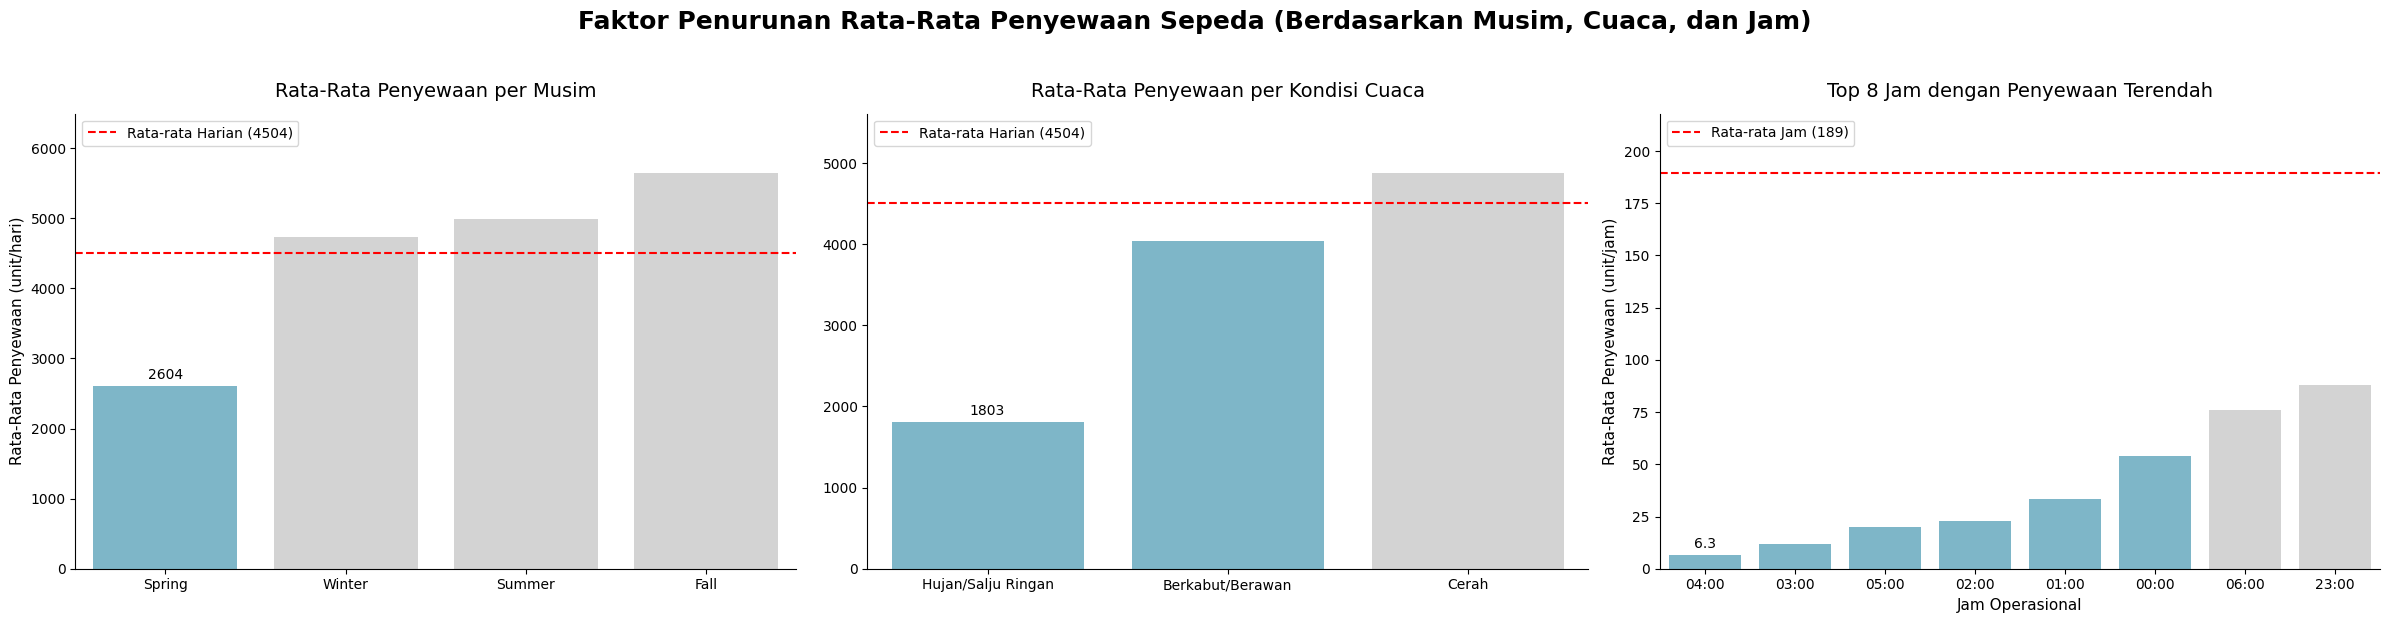

In [184]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(24, 6))
fig.suptitle("Faktor Penurunan Rata-Rata Penyewaan Sepeda (Berdasarkan Musim, Cuaca, dan Jam)", fontsize=18, fontweight="bold", y=1.03)

plot_season = eda_season.sort_values(by="cnt_day", ascending=True).reset_index()
plot_season["clean_season"] = plot_season["season_label"].str.split("_").str[1]
season_colors = ["#72BCD4" if val < baseline_day else "#D3D3D3" for val in plot_season["cnt_day"]]

sns.barplot(
    x="clean_season", y="cnt_day", hue="clean_season",
    data=plot_season, palette=season_colors, legend=False, ax=ax[0]
)
ax[0].axhline(baseline_day, color="red", linestyle="--", linewidth=1.5, label=f"Rata-rata Harian ({baseline_day:.0f})")
ax[0].set_title("Rata-Rata Penyewaan per Musim", fontsize=14, pad=12)
ax[0].set_xlabel(None)
ax[0].set_ylabel("Rata-Rata Penyewaan (unit/hari)", fontsize=11)
ax[0].set_ylim(0, plot_season["cnt_day"].max() * 1.15)
ax[0].legend(loc="upper left")
ax[0].bar_label(ax[0].containers[0], fmt="%.0f", padding=3, fontsize=10)

plot_weather = eda_weather["mean"][["cnt_day"]].sort_values(by="cnt_day", ascending=True).reset_index()
plot_weather["clean_weather"] = plot_weather["weather_label"].str.split("_").str[1].replace({
    "Cerah/Berawan Sedikit": "Cerah",
    "Berkabut/Berawan": "Berkabut/Berawan",
    "Hujan/Salju Ringan": "Hujan/Salju Ringan"
})
weather_colors = ["#72BCD4" if val < baseline_day else "#D3D3D3" for val in plot_weather["cnt_day"]]

sns.barplot(
    x="clean_weather", y="cnt_day", hue="clean_weather",
    data=plot_weather, palette=weather_colors, legend=False, ax=ax[1]
)
ax[1].axhline(baseline_day, color="red", linestyle="--", linewidth=1.5, label=f"Rata-rata Harian ({baseline_day:.0f})")
ax[1].set_title("Rata-Rata Penyewaan per Kondisi Cuaca", fontsize=14, pad=12)
ax[1].set_xlabel(None)
ax[1].set_ylabel(None)
ax[1].set_ylim(0, plot_weather["cnt_day"].max() * 1.15)
ax[1].legend(loc="upper left")
ax[1].bar_label(ax[1].containers[0], fmt="%.0f", padding=3, fontsize=10)

plot_hour = eda_hour.sort_values(by="cnt_hour", ascending=True).head(8).reset_index()
plot_hour["hr_label"] = plot_hour["hr"].astype(str).str.zfill(2) + ":00"
hour_colors = ["#72BCD4" if hr <= 5 else "#D3D3D3" for hr in plot_hour["hr"]]

sns.barplot(
    x="hr_label", y="cnt_hour", hue="hr_label",
    data=plot_hour, palette=hour_colors, legend=False, ax=ax[2]
)
ax[2].axhline(baseline_hour, color="red", linestyle="--", linewidth=1.5, label=f"Rata-rata Jam ({baseline_hour:.0f})")
ax[2].set_title("Top 8 Jam dengan Penyewaan Terendah", fontsize=14, pad=12)
ax[2].set_xlabel("Jam Operasional", fontsize=11)
ax[2].set_ylabel("Rata-Rata Penyewaan (unit/jam)", fontsize=11)
ax[2].set_ylim(0, baseline_hour * 1.15)
ax[2].legend(loc="upper left")
ax[2].bar_label(ax[2].containers[0], fmt="%.1f", padding=3, fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Seberapa besar perbedaan rata-rata jumlah penyewaan sepeda antara musim panas dan musim dingin pada kondisi cuaca cerah dan buruk selama tahun 2011–2012?

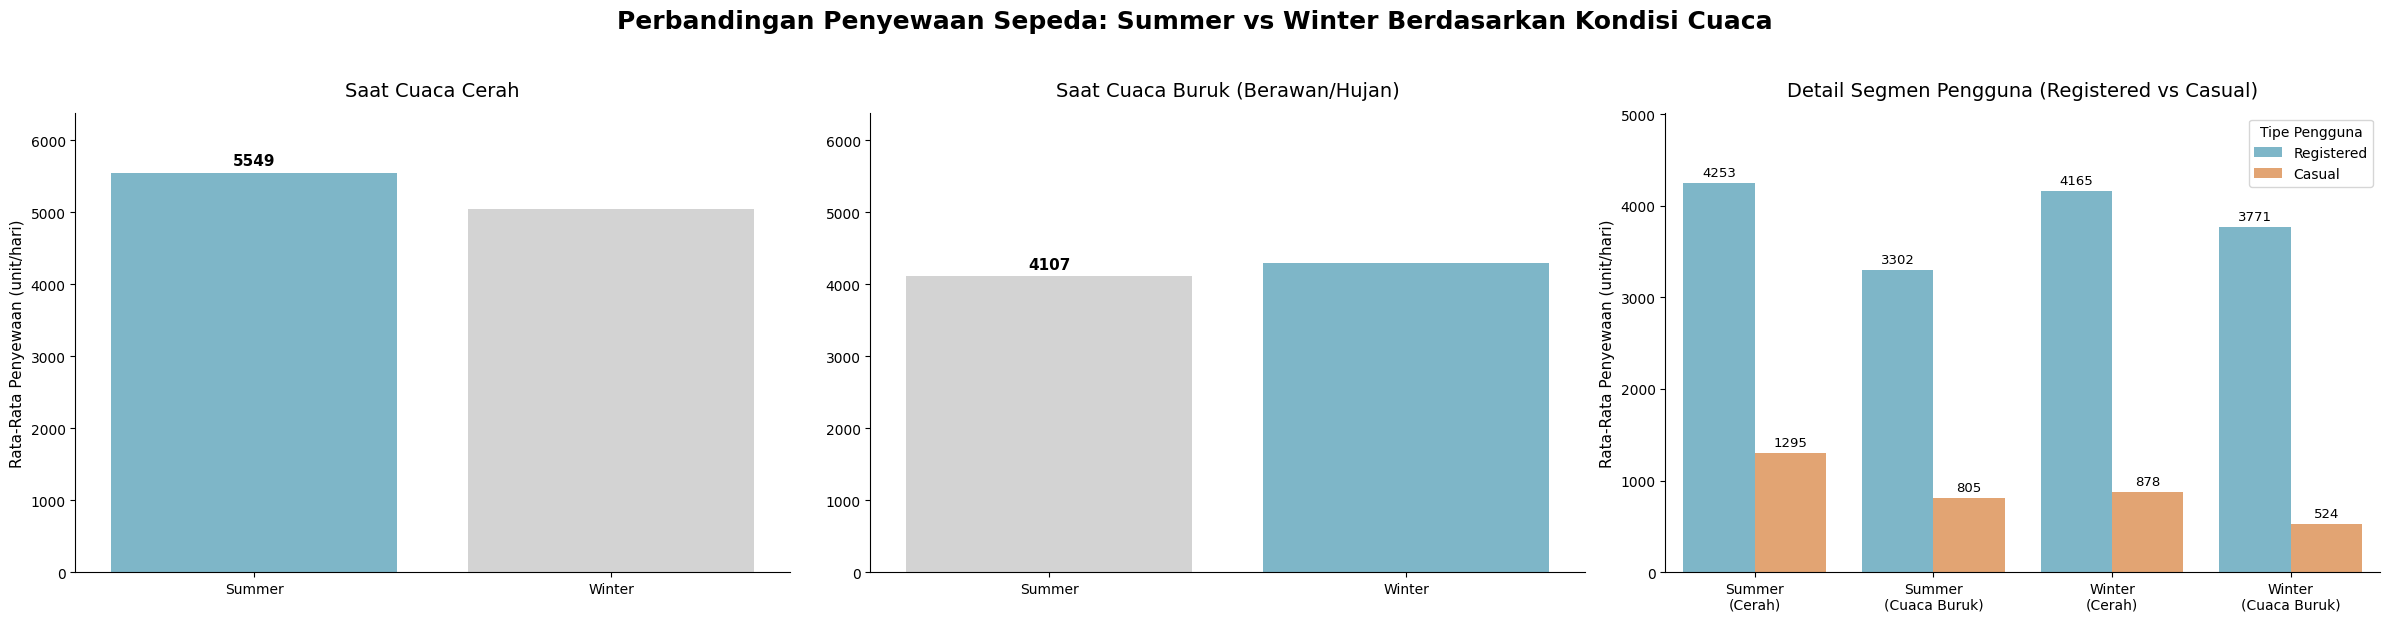

In [185]:
plot_sw_total = eda_sw_total["mean"].reset_index()
plot_sw_total["clean_season"] = plot_sw_total["season_label"].str.split("_").str[1]

plot_sw_user = eda_sw_user.reset_index()
plot_sw_user["clean_season"] = plot_sw_user["season_label"].str.split("_").str[1]
plot_sw_user["clean_weather"] = plot_sw_user["kondisi_cuaca"].replace({
    "1_Cerah": "Cerah",
    "2_Cuaca_Buruk (Berawan/Hujan)": "Cuaca Buruk"
})
plot_sw_user["Segmen"] = plot_sw_user["clean_season"] + "\n(" + plot_sw_user["clean_weather"] + ")"

plot_sw_melted = plot_sw_user.melt(
    id_vars=["Segmen"],
    value_vars=["registered_day", "casual_day"],
    var_name="Tipe_Pengguna",
    value_name="Rata_Rata"
)
plot_sw_melted["Tipe_Pengguna"] = plot_sw_melted["Tipe_Pengguna"].replace({
    "registered_day": "Registered",
    "casual_day": "Casual"
})

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(24, 6))
fig.suptitle("Perbandingan Penyewaan Sepeda: Summer vs Winter Berdasarkan Kondisi Cuaca", fontsize=18, fontweight="bold", y=1.03)

max_y_total = plot_sw_total[["1_Cerah", "2_Cuaca_Buruk (Berawan/Hujan)"]].max().max() * 1.15

sns.barplot(
    x="clean_season", y="1_Cerah", hue="clean_season",
    data=plot_sw_total, palette=["#72BCD4", "#D3D3D3"], legend=False, ax=ax[0]
)
ax[0].set_title("Saat Cuaca Cerah", fontsize=14, pad=12)
ax[0].set_xlabel(None)
ax[0].set_ylabel("Rata-Rata Penyewaan (unit/hari)", fontsize=11)
ax[0].set_ylim(0, max_y_total)
ax[0].bar_label(ax[0].containers[0], fmt="%.0f", padding=3, fontsize=11, fontweight="bold")

sns.barplot(
    x="clean_season", y="2_Cuaca_Buruk (Berawan/Hujan)", hue="clean_season",
    data=plot_sw_total, palette=["#D3D3D3", "#72BCD4"], legend=False, ax=ax[1]
)
ax[1].set_title("Saat Cuaca Buruk (Berawan/Hujan)", fontsize=14, pad=12)
ax[1].set_xlabel(None)
ax[1].set_ylabel(None)
ax[1].set_ylim(0, max_y_total)
ax[1].bar_label(ax[1].containers[0], fmt="%.0f", padding=3, fontsize=11, fontweight="bold")

sns.barplot(
    x="Segmen", y="Rata_Rata", hue="Tipe_Pengguna",
    data=plot_sw_melted, palette=["#72BCD4", "#F4A261"], ax=ax[2]
)
ax[2].set_title("Detail Segmen Pengguna (Registered vs Casual)", fontsize=14, pad=12)
ax[2].set_xlabel(None)
ax[2].set_ylabel("Rata-Rata Penyewaan (unit/hari)", fontsize=11)
ax[2].set_ylim(0, plot_sw_melted["Rata_Rata"].max() * 1.18)
ax[2].legend(title="Tipe Pengguna", loc="upper right")

for container in ax[2].containers:
    ax[2].bar_label(container, fmt="%.0f", padding=3, fontsize=9.5)

sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Terdapat tiga penyebab utama yang menekan volume penyewaan sepeda hingga berada di bawah ambang rata-rata harian (4.504 unit) maupun per jam (189 unit), yaitu datangnya musim Spring yang merosot ke level 2.604 unit/hari, kondisi Hujan/Salju Ringan yang menurunkan minat sewa secara drastis menjadi 1.803 unit/hari (diikuti cuaca Berkabut/Berawan), serta periode waktu dini hari antara pukul 00:00 hingga 05:00 dengan titik terendah pada pukul 04:00 sebesar 6,3 unit/jam
- Walaupun musim Summer mendominasi penyewaan saat Cuaca Cerah (5.549 unit/hari) karena dorongan tingginya pengguna casual (1.295 unit/hari), musim Winter justru mencatatkan performa lebih unggul ketika Cuaca Buruk terjadi dibandingkan Summer yang melemah ke posisi 4.107 unit/hari. Daya tahan Winter di tengah cuaca yang kurang bersahabat ini berasal dari konsistensi segmen pengguna registered yang tetap stabil di angka 3.771 unit/hari, berbanding terbalik dengan Summer yang mengalami penyusutan signifikan dari 4.253 menjadi 3.302 unit/hari

## Analisis Lanjutan (Opsional)

Manual Grouping (Mengelompokkan seluruh catatan waktu per jam (hour_clean) ke dalam 3 klaster tingkat permintaan (Low Demand, Medium Demand, High Demand), lalu membandingkan karakteristik cuaca dan segmen penggunanya)

=== Ringkasan Profil Tiap Klaster Permintaan (hour_clean) ===
Demand_Cluster  Jumlah_Jam  Rata_Rata_Total  Rata_Rata_Casual  Rata_Rata_Registered  Rata_Rata_Suhu  Rata_Rata_Kelembapan
    Low Demand        5797            25.06              3.68                 21.38            0.41                  0.72
 Medium Demand        5823           144.31             24.71                119.60            0.48                  0.62
   High Demand        5759           400.61             78.98                321.63            0.60                  0.55


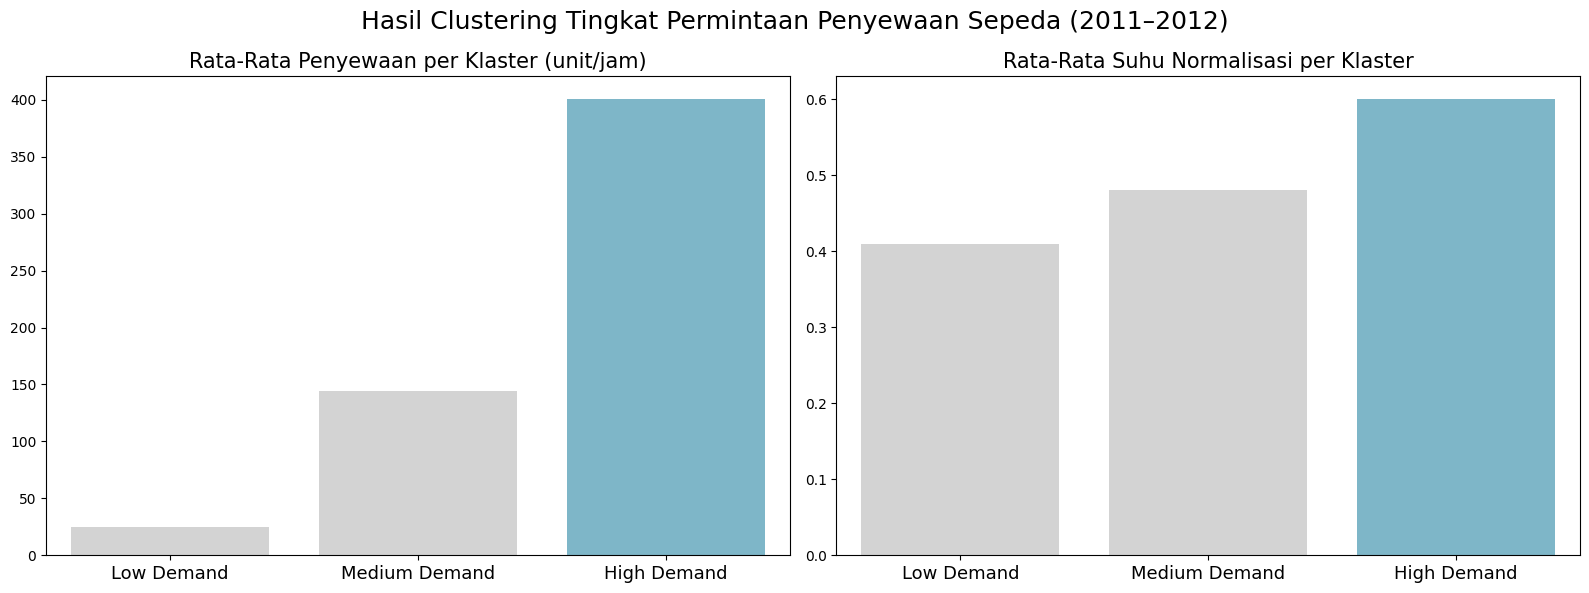

In [186]:
df_cluster = hour_clean.copy()

df_cluster['Demand_Cluster'] = pd.qcut(
    df_cluster['cnt'],
    q=3,
    labels=['Low Demand', 'Medium Demand', 'High Demand']
)

cluster_summary = df_cluster.groupby('Demand_Cluster', observed=False).agg(
    Jumlah_Jam=('cnt', 'count'),
    Rata_Rata_Total=('cnt', 'mean'),
    Rata_Rata_Casual=('casual', 'mean'),
    Rata_Rata_Registered=('registered', 'mean'),
    Rata_Rata_Suhu=('temp', 'mean'),
    Rata_Rata_Kelembapan=('hum', 'mean')
).round(2).reset_index()

print("=== Ringkasan Profil Tiap Klaster Permintaan (hour_clean) ===")
print(cluster_summary.to_string(index=False))

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

sns.barplot(
    x='Demand_Cluster', y='Rata_Rata_Total', hue='Demand_Cluster',
    data=cluster_summary, palette=['#D3D3D3', '#D3D3D3', '#72BCD4'],
    legend=False, ax=ax[0]
)
ax[0].set_title('Rata-Rata Penyewaan per Klaster (unit/jam)', fontsize=15)
ax[0].set_xlabel(None)
ax[0].set_ylabel(None)
ax[0].tick_params(axis='x', labelsize=13)

sns.barplot(
    x='Demand_Cluster', y='Rata_Rata_Suhu', hue='Demand_Cluster',
    data=cluster_summary, palette=['#D3D3D3', '#D3D3D3', '#72BCD4'],
    legend=False, ax=ax[1]
)
ax[1].set_title('Rata-Rata Suhu Normalisasi per Klaster', fontsize=15)
ax[1].set_xlabel(None)
ax[1].set_ylabel(None)
ax[1].tick_params(axis='x', labelsize=13)

plt.suptitle('Hasil Clustering Tingkat Permintaan Penyewaan Sepeda (2011–2012)', fontsize=18)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Rata-rata penyewaan pada klaster High Demand mencapai 400,61 unit/jam, melonjak hampir 16 kali lipat dibandingkan Low Demand yang dimana mencapai 25,06 unit/jam dan 2,8 kali lipat dibandingkan Medium Demand yang dimana juga mencapai 144,31 unit/jam, yang didorong oleh dominasi pengguna terdaftar yaitu 321,63 unit/jam serta kenaikan tajam pengguna kasual yaitu 78,98 unit/jam
- Pengaruh Suhu Hangat dan Udara Kering: Kenaikan permintaan berbanding lurus dengan suhu udara dan berbanding terbalik dengan kelembapan, di mana klaster High Demand terjadi pada kondisi suhu yang lebih hangat (0,60) dan kelembapan rendah (0,55), sedangkan Low Demand terjadi saat suhu dingin (0,41) dan kelembapan tinggi (0,72)

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan rata-rata keseluruhan sebesar 4.504,35 penyewaan/hari dan 189,46 penyewaan/jam selama tahun 2011 - 2012, penurunan penyewaan sepeda minimal 10% pada faktor musim hanya terjadi saat musim semi (Spring) dengan penurunan sebesar 42,19%. Dari faktor cuaca, penurunan signifikan terjadi ketika cuaca berkabut/berawan (-10,40% pada skala harian), hujan/salju ringan (-59,97% harian dan -41,11% per jam), serta cuaca ekstrem (-60,77% per jam). Sementara itu, pada faktor waktu, penurunan tajam berlangsung di jam malam hingga dini hari pukul 22:00–06:00 dengan titik terendah pada pukul 04:00, sedangkan berdasarkan hari dalam seminggu tidak ada yang turun hingga 10% karena penurunan terdalam hanya terjadi di hari Minggu sebesar -6,12%.

- **Conclusion pertanyaan 2:** Perbandingan penyewaan sepeda antara musim panas (Summer) dan musim dingin (Winter) selama tahun 2011 - 2012 memperlihatkan pola yang berkebalikan tergantung kondisi cuacanya. Saat cuaca cerah, rata-rata penyewaan di musim panas (5.548,55 unit/hari) lebih tinggi sebesar 504,99 unit/hari atau unggul 10,01% dibandingkan musim dingin (5.043,56 unit/hari). Sebaliknya, ketika cuaca buruk, rata-rata penyewaan di musim dingin (4.295,01 unit/hari) justru lebih tinggi 187,93 unit/hari dibandingkan musim panas (4.107,08 unit/hari), dengan keunggulan musim dingin sebesar 8,97% pada kondisi berkabut/berawan dan melebar hingga 40,41% saat hujan/salju ringan.

**Rekomendasi Action Item:**
- Strategi Promosi dan Efisiensi Operasional pada Musim Semi (Spring)
- Optimalisasi Kapasitas pada Cuaca Cerah Musim Panas (Summer)
- Mitigasi Dampak Cuaca Buruk Berbasis Prediksi